# SeaweedMat E06 — Techno-economic and environmental assessment
Run with the supplied LCA and TEA dataset.xlsx in this directory or its parent. Source cached cell values are read without modifying the workbook. Replacement scenarios are illustrative and dimensionless.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import csv, json, hashlib, math, sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT=Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
SOURCE=Path(sys.argv[1]) if '__file__' in globals() and len(sys.argv)>1 else ROOT/'LCA and TEA dataset.xlsx'
if not SOURCE.exists(): SOURCE=ROOT.parent/'LCA and TEA dataset.xlsx'
OUT=ROOT/'outputs'; OUT.mkdir(exist_ok=True)
NS={'m':'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
with ZipFile(SOURCE) as z:
    strings=[''.join(s.itertext()) for s in ET.fromstring(z.read('xl/sharedStrings.xml'))]
    names=[s.get('name') for s in ET.fromstring(z.read('xl/workbook.xml')).findall('.//m:sheet',NS)]
    sheets={}
    for i,name in enumerate(names,1):
        d={}
        for c in ET.fromstring(z.read(f'xl/worksheets/sheet{i}.xml')).findall('.//m:c',NS):
            v=c.find('m:v',NS)
            if v is not None and v.text is not None:
                d[c.get('r')]=strings[int(v.text)] if c.get('t')=='s' else float(v.text) if c.get('t') not in ('e','str','b') else v.text
        sheets[name]=d

def save(name,rows):
    with (OUT/name).open('w',newline='',encoding='utf-8') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)

def r(x):return round(x,8)
labels=['Concrete net','Heavy chain net','Light chain net','Longline']
bio=sheets['Biomass composition']; lca=sheets['LCIA comparison']; group=sheets['Groupped contribution']
systems=[]; impacts=[]
for i,label in enumerate(labels):
    b='BCDE'[i]; c='CDEF'[i]; gr=[2,20,38,56][i]; fw=bio[b+'11']; dw=bio[b+'12']; site=lca[c+'3']; gp=group['P'+str(gr)]
    systems.append(dict(system=label,area_ha=18.75,fresh_biomass_kg=fw,dry_biomass_kg=dw,gwp_site_kg_co2eq=r(site),gwp_per_kg_FW=r(lca[c+'47']),gwp_per_kg_DW=r(lca[c+'69']),gwp_per_kg_FW_recomputed=r(site/fw),net_line_group_gwp_kg_co2eq=r(group['G'+str(gr)]),net_line_group_share_pct=r(100*group['G'+str(gr)]/gp),flotation_share_pct=r(100*group['N'+str(gr)]/gp),source=f'Biomass composition {b}11:{b}12; LCIA comparison {c}3,{c}47,{c}69; Groupped contribution G{gr},N{gr},P{gr}'))
    for j in range(18):
        row=j+3; impacts.append(dict(system=label,category=lca['A'+str(row)],unit=lca['B'+str(row)],per_site_year=lca[c+str(row)],per_kg_FW=lca[c+str(row+44)],per_kg_DW=lca[c+str(row+66)],source=f'LCIA comparison {c}{row},{c}{row+44},{c}{row+66}'))
save('systems.csv',systems);save('lcia_18_categories.csv',impacts)
assert all(abs(x['gwp_per_kg_FW']-x['gwp_per_kg_FW_recomputed'])<1e-7 for x in systems)
npvs=[]; cash=[]
for i,label in enumerate(labels):
    line=i==3; d=sheets['NPV_Line' if line else 'NPV_Net']; sheet='NPV_Line' if line else 'NPV_Net'
    for case in range(3):
        if line: start,end=10,20; rate=d['L8']; price=d['H'+str(24+case)]; cap,op1,op2,rev='D','E','F','GHI'[case]; source='AB'+str(9+case); cum='RUX'[case]+str(end)
        else: start,end=[(7,17),(27,37),(46,56)][case]; rate=d[['P4','P24','P43'][case]]; price=d[['M20','M40','M59'][case]]; cap,op1,op2,rev='FGH'[i],'I','J','KLM'[i]; source='AG'+str([5,25,44][case]+i); cum=['Z','AB','AD'][i]+str(end)
        costpv=revpv=0
        for row in range(start,end+1):
            t=int(d['A'+str(row)]); cp=d.get(cap+str(row),0); op=d.get(op1+str(row),0)+d.get(op2+str(row),0); revenue=d.get(rev+str(row),0); disc=(1+rate)**t; costpv-=(cp+op)/disc; revpv+=revenue/disc
            cash.append(dict(system=label,case=case+1,year=t,capex_EUR=cp,opex_EUR=op,revenue_EUR=revenue,discounted_net_cashflow_EUR=(cp+op+revenue)/disc,source=f'{sheet} row {row}'))
        npv=revpv-costpv; reported=d[source]; assert abs(npv-reported)<1e-5
        npvs.append(dict(system=label,case=case+1,sale_price_EUR_per_kg_DW=r(price),discount_rate=rate,years=10,reported_npv_EUR=r(reported),recalculated_npv_EUR=r(npv),discounted_cost_EUR=r(costpv),discounted_revenue_EUR=r(revpv),break_even_price_EUR_per_kg_DW=r(costpv/(revpv/price)),source_final_cumulative_EUR=r(d[cum]),cumulative_minus_recalculated_EUR=r(d[cum]-npv),source=f'{sheet} {source}; cash flows rows {start}-{end}; cumulative {cum}'))
save('npv_audit.csv',npvs);save('annual_cashflows.csv',cash)
sens=sheets['Sensitivity analysis']; sensitivity=[]
for scenario,rr in [('Smaller pipe (110 mm)',[7,25,43,61]),('Ecoinvent shipping container',[87,105,123,141]),('Five-year net/line lifetime',[164,182,200,218]),('Combined lifetime and smaller pipe',[240,258,276,294])]:
    for label,row in zip(labels,rr):
        sensitivity.append(dict(scenario=scenario,system=label,gwp_site_kg_co2eq=r(sens['P'+str(row)]),reported_change_pct=r(sens['Q'+str(row)]),source=f'Sensitivity analysis P{row}:Q{row}'))
save('source_sensitivity.csv',sensitivity)
# Source-defined line and net purchase cost, not actual prices for candidate materials in Tanzania.
inv=[]
for sheet,rr,cols in [('Net set-up inventory',[22],('C','D','E','F','G')),('Line set-up inventory',[20],('C','D','E','F','G')),('Net set-up inventory',[57,58,59,62,68,71,72],('B','C','D','E','F')),('Line set-up inventory',[56,59,65],('B','C','D','E','F'))]:
    d=sheets[sheet]
    for row in rr:
        q,u,life,p,annual=[d[c+str(row)] for c in cols]
        inv.append(dict(system=sheet,component=d['A'+str(row)],quantity=q,unit=u,lifetime_as_listed=life,purchase_price_DKK_per_unit=p,reported_cost_column_DKK=annual,quantity_times_price_DKK=q*p,source=f'{sheet} row {row}',note='Source cost column uses five-year allocation for net/seeded line despite listed lifetime 1; not a measured replacement schedule' if row in (20,22) else 'Source allocated cost column preserved; not local price'))
save('rope_inventory.csv',inv)
# Dimensionless illustrative scenario; same rope length and no labour, or include relative labour with a separate formula.
scenarios=[]
for life in [.25,.5,1,1.5,2]:
    for price in [.5,1,1.5,2]:
        for yield_ratio in [.8,1,1.2]:
            scenarios.append(dict(lifetime_ratio=life,price_per_m_ratio=price,marketable_yield_ratio=yield_ratio,material_cost_per_output_ratio=r(price/life/yield_ratio),break_even_price_ratio=r(life*yield_ratio),status='illustrative scenario; not measured'))
save('replacement_scenarios.csv',scenarios)
# A dimensionless carbon screen requires measured material manufacture/disposal intensity; no material emission factors invented.
carbon=[]
for life in [.25,.5,1,1.5,2]:
    for yield_ratio in [.8,1,1.2]:carbon.append(dict(lifetime_ratio=life,marketable_yield_ratio=yield_ratio,max_candidate_impact_per_m_ratio=r(life*yield_ratio),scope='replacement component only; same installed length; no transport/labour/other impacts'))
save('environmental_break_even.csv',carbon)
plt.rcParams.update({'font.family':'DejaVu Sans','font.weight':'bold','axes.labelweight':'bold','axes.labelsize':13,'font.size':11,'axes.linewidth':2,'xtick.major.width':2,'ytick.major.width':2,'xtick.major.size':5,'ytick.major.size':5,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none'})
def export(fig,name):
    fig.tight_layout()
    for ext in ['png','svg','pdf']:fig.savefig(OUT/f'{name}.{ext}',dpi=600,facecolor='white',bbox_inches='tight')
    plt.close(fig)
fig,ax=plt.subplots(figsize=(160/25.4,100/25.4)); vals=[x['gwp_per_kg_FW'] for x in systems]; bars=ax.barh(labels,vals,color=['#075DE8']*3+['#008D79']);ax.invert_yaxis();ax.set_xlabel('Global warming [kg CO₂ eq/kg FW]');ax.set_xlim(0,1.38);ax.bar_label(bars,fmt='%.3f',padding=4,fontweight='bold');export(fig,'gwp_comparison')
fig,ax=plt.subplots(figsize=(160/25.4,100/25.4)); vals=[x['break_even_price_EUR_per_kg_DW'] for x in npvs if x['case']==1];bars=ax.barh(labels,vals,color=['#075DE8']*3+['#008D79']);ax.invert_yaxis();ax.set_xlabel('Break-even selling price [EUR/kg DW]');ax.set_xlim(0,max(vals)*1.23);ax.bar_label(bars,fmt='%.2f',padding=4,fontweight='bold');export(fig,'break_even_price')
fig,ax=plt.subplots(figsize=(150/25.4,115/25.4)); xs=[.25,.5,1,1.5,2];
for y,c in zip([.8,1,1.2],['#D97706','#075DE8','#008D79']):ax.plot(xs,[x*y for x in xs],marker='o',lw=2.5,color=c,label=f'Yield ratio = {y:.1f}')
ax.set_xlabel('Candidate / reference service life');ax.set_ylabel('Break-even unit-price ratio');ax.legend(frameon=False);export(fig,'replacement_break_even')
# Verify same functional units, all three NPV cases use same costs, and price thresholds agree.
for label in labels:
    vals=[x['break_even_price_EUR_per_kg_DW'] for x in npvs if x['system']==label];assert max(vals)-min(vals)<1e-5
lower=sum(all(next(x['per_kg_FW'] for x in impacts if x['system']=='Longline' and x['category']==cat)<next(x['per_kg_FW'] for x in impacts if x['system']==s and x['category']==cat) for s in labels[:3]) for cat in {x['category'] for x in impacts})
audit={'source_file':SOURCE.name,'sha256':hashlib.sha256(SOURCE.read_bytes()).hexdigest(),'sheets':len(names),'systems':4,'impact_categories':18,'lcia_records':72,'npv_recomputed':12,'annual_cashflow_rows':len(cash),'npv_summary_agreement':True,'cumulative_balance_discrepancies_gt_1EUR':sum(abs(x['cumulative_minus_recalculated_EUR'])>1 for x in npvs),'longline_lowest_all_three_nets_categories_per_FW':lower,'source_sensitivity_rows':len(sensitivity),'replacement_scenarios':len(scenarios),'local_prices_or_service_lives_measured':False}
(OUT/'audit.json').write_text(json.dumps(audit,indent=2)+'\n');print(json.dumps(audit,indent=2));print('\nSystem summary:');print(*systems,sep='\n');print('\nCase 1:');print(*[x for x in npvs if x['case']==1],sep='\n')


{
  "source_file": "LCA and TEA dataset.xlsx",
  "sha256": "9b421e1d239baeebf860a1284eee381cdb2bd2d111b14af463b711beb29d2a3c",
  "sheets": 15,
  "systems": 4,
  "impact_categories": 18,
  "lcia_records": 72,
  "npv_recomputed": 12,
  "annual_cashflow_rows": 132,
  "npv_summary_agreement": true,
  "cumulative_balance_discrepancies_gt_1EUR": 7,
  "longline_lowest_all_three_nets_categories_per_FW": 18,
  "source_sensitivity_rows": 16,
  "replacement_scenarios": 60,
  "local_prices_or_service_lives_measured": false
}

System summary:
{'system': 'Concrete net', 'area_ha': 18.75, 'fresh_biomass_kg': 69199.20000000001, 'dry_biomass_kg': 7750.310400000001, 'gwp_site_kg_co2eq': 66535.80231674, 'gwp_per_kg_FW': 0.96151115, 'gwp_per_kg_DW': 8.58492098, 'gwp_per_kg_FW_recomputed': 0.96151115, 'net_line_group_gwp_kg_co2eq': 8894.36042438, 'net_line_group_share_pct': 13.36783944, 'flotation_share_pct': 64.26944119, 'source': 'Biomass composition B11:B12; LCIA comparison C3,C47,C69; Groupped contribu

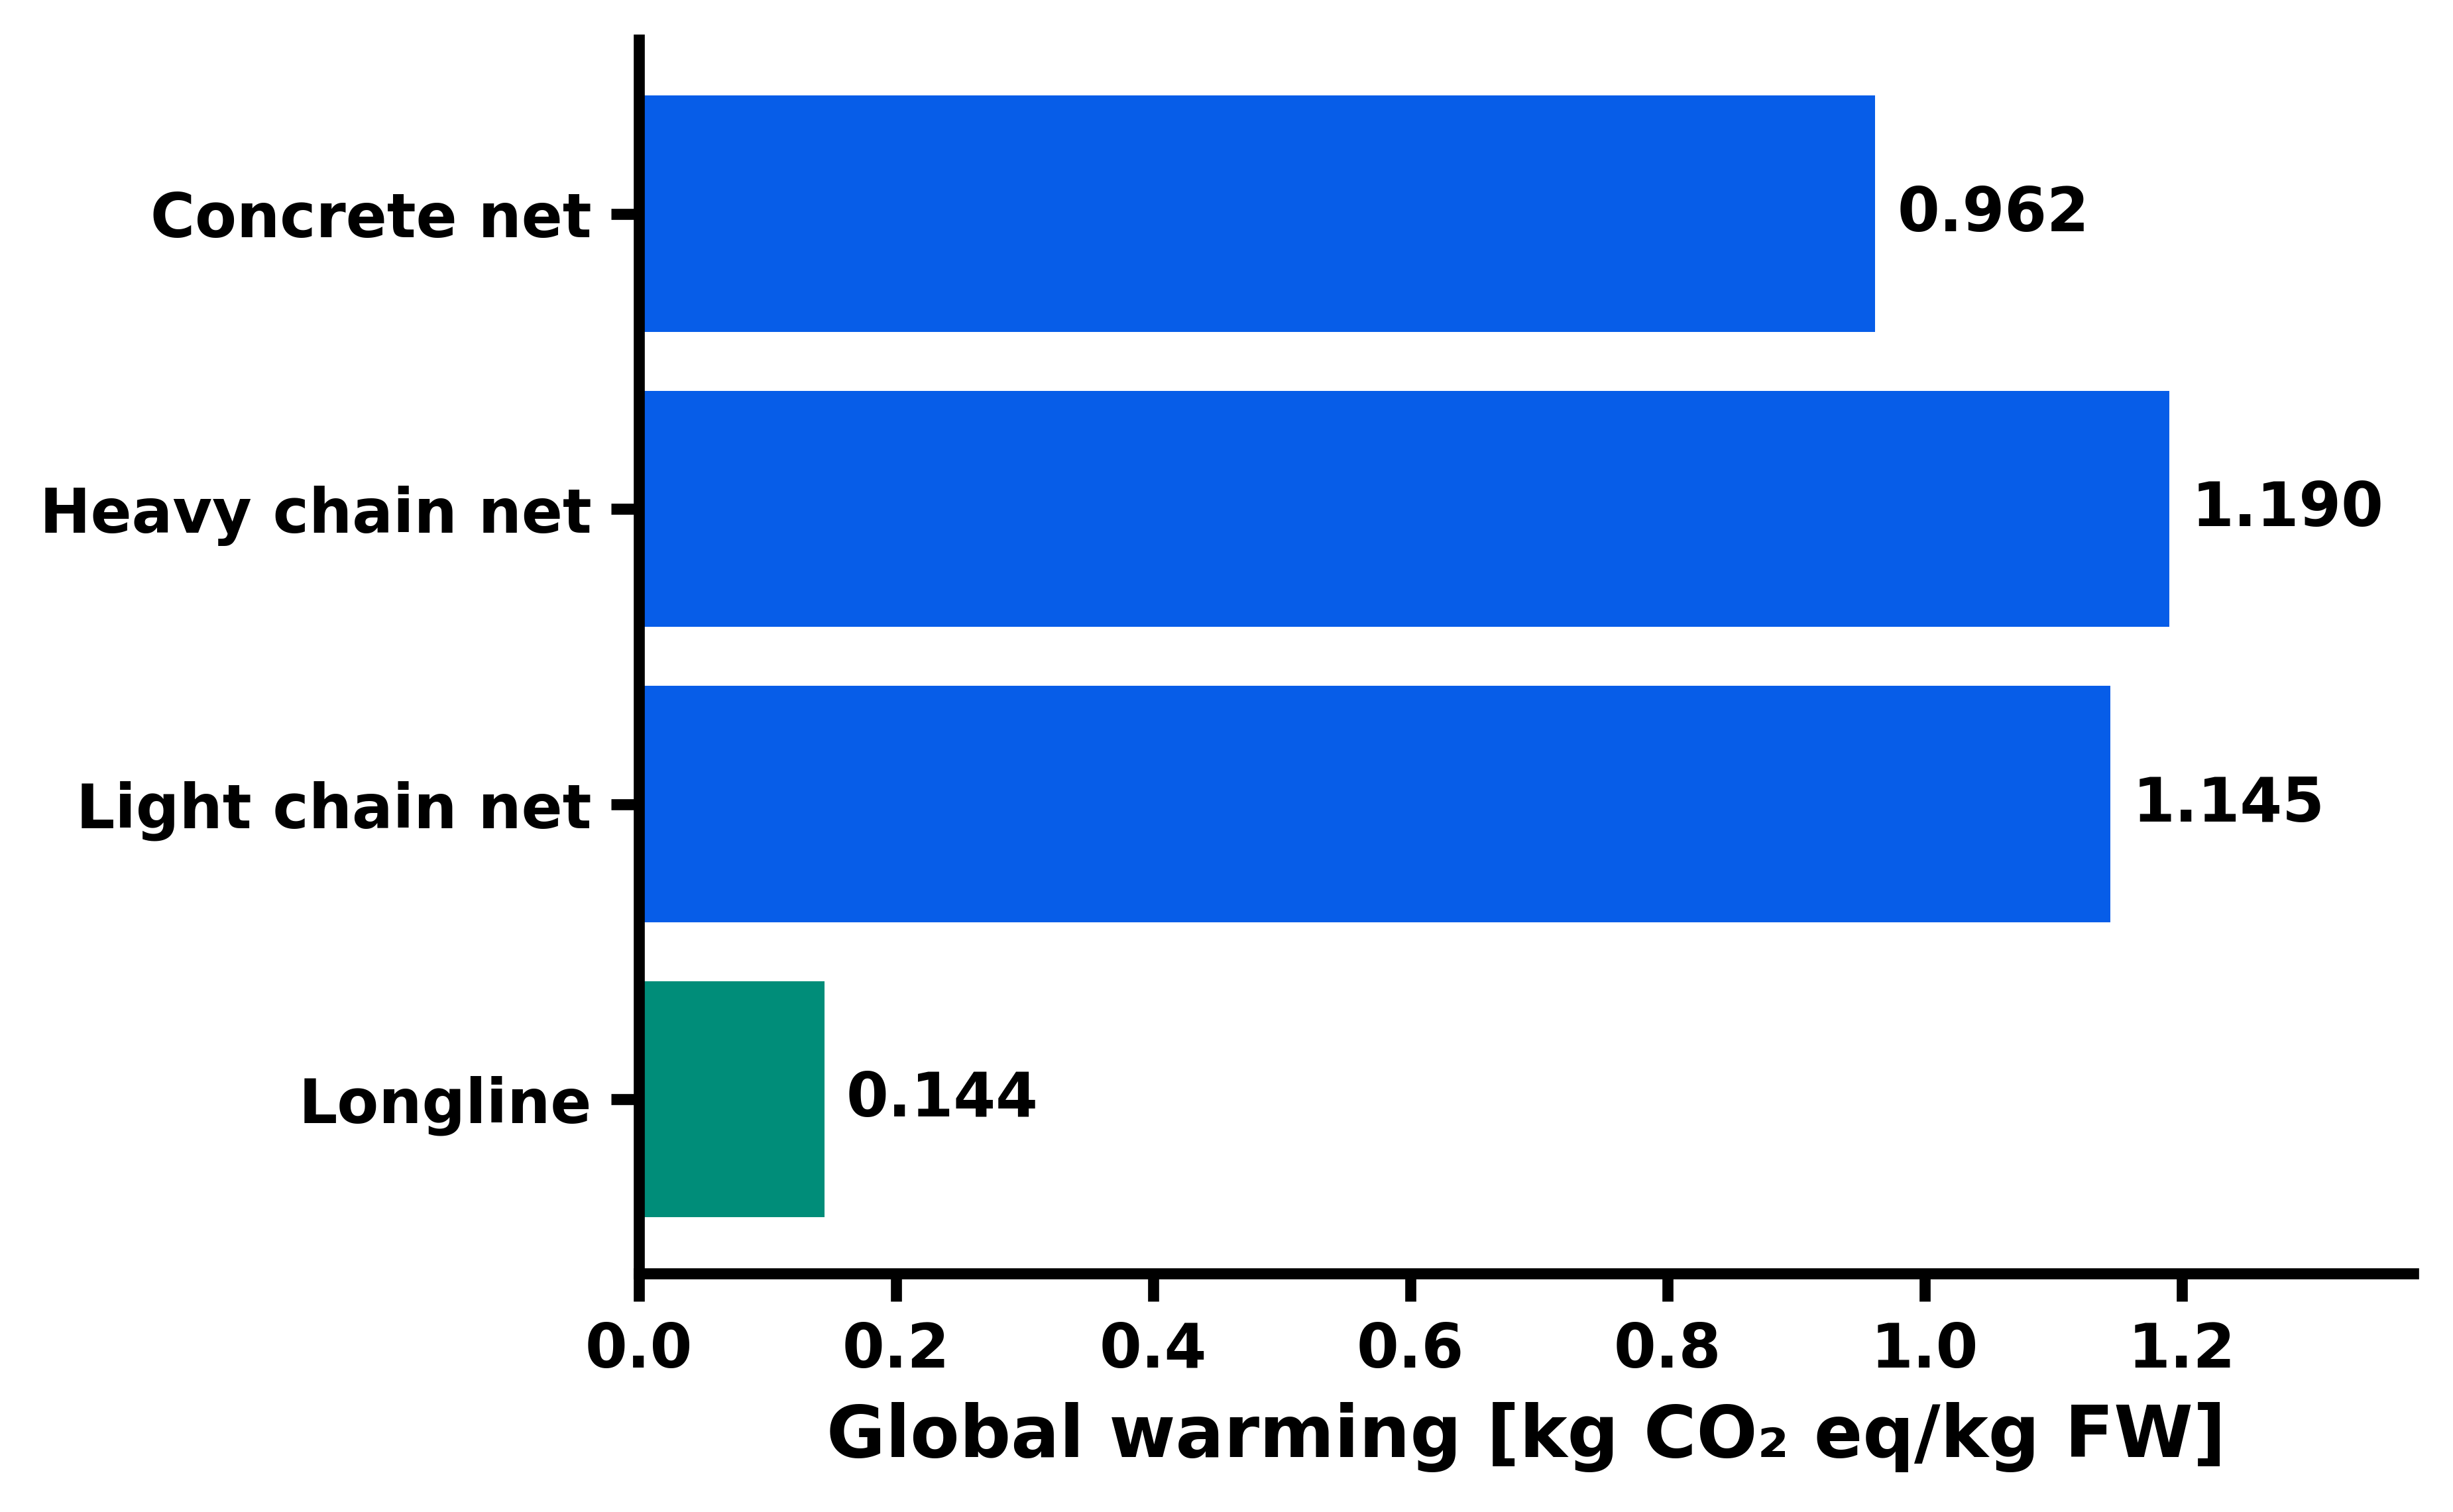

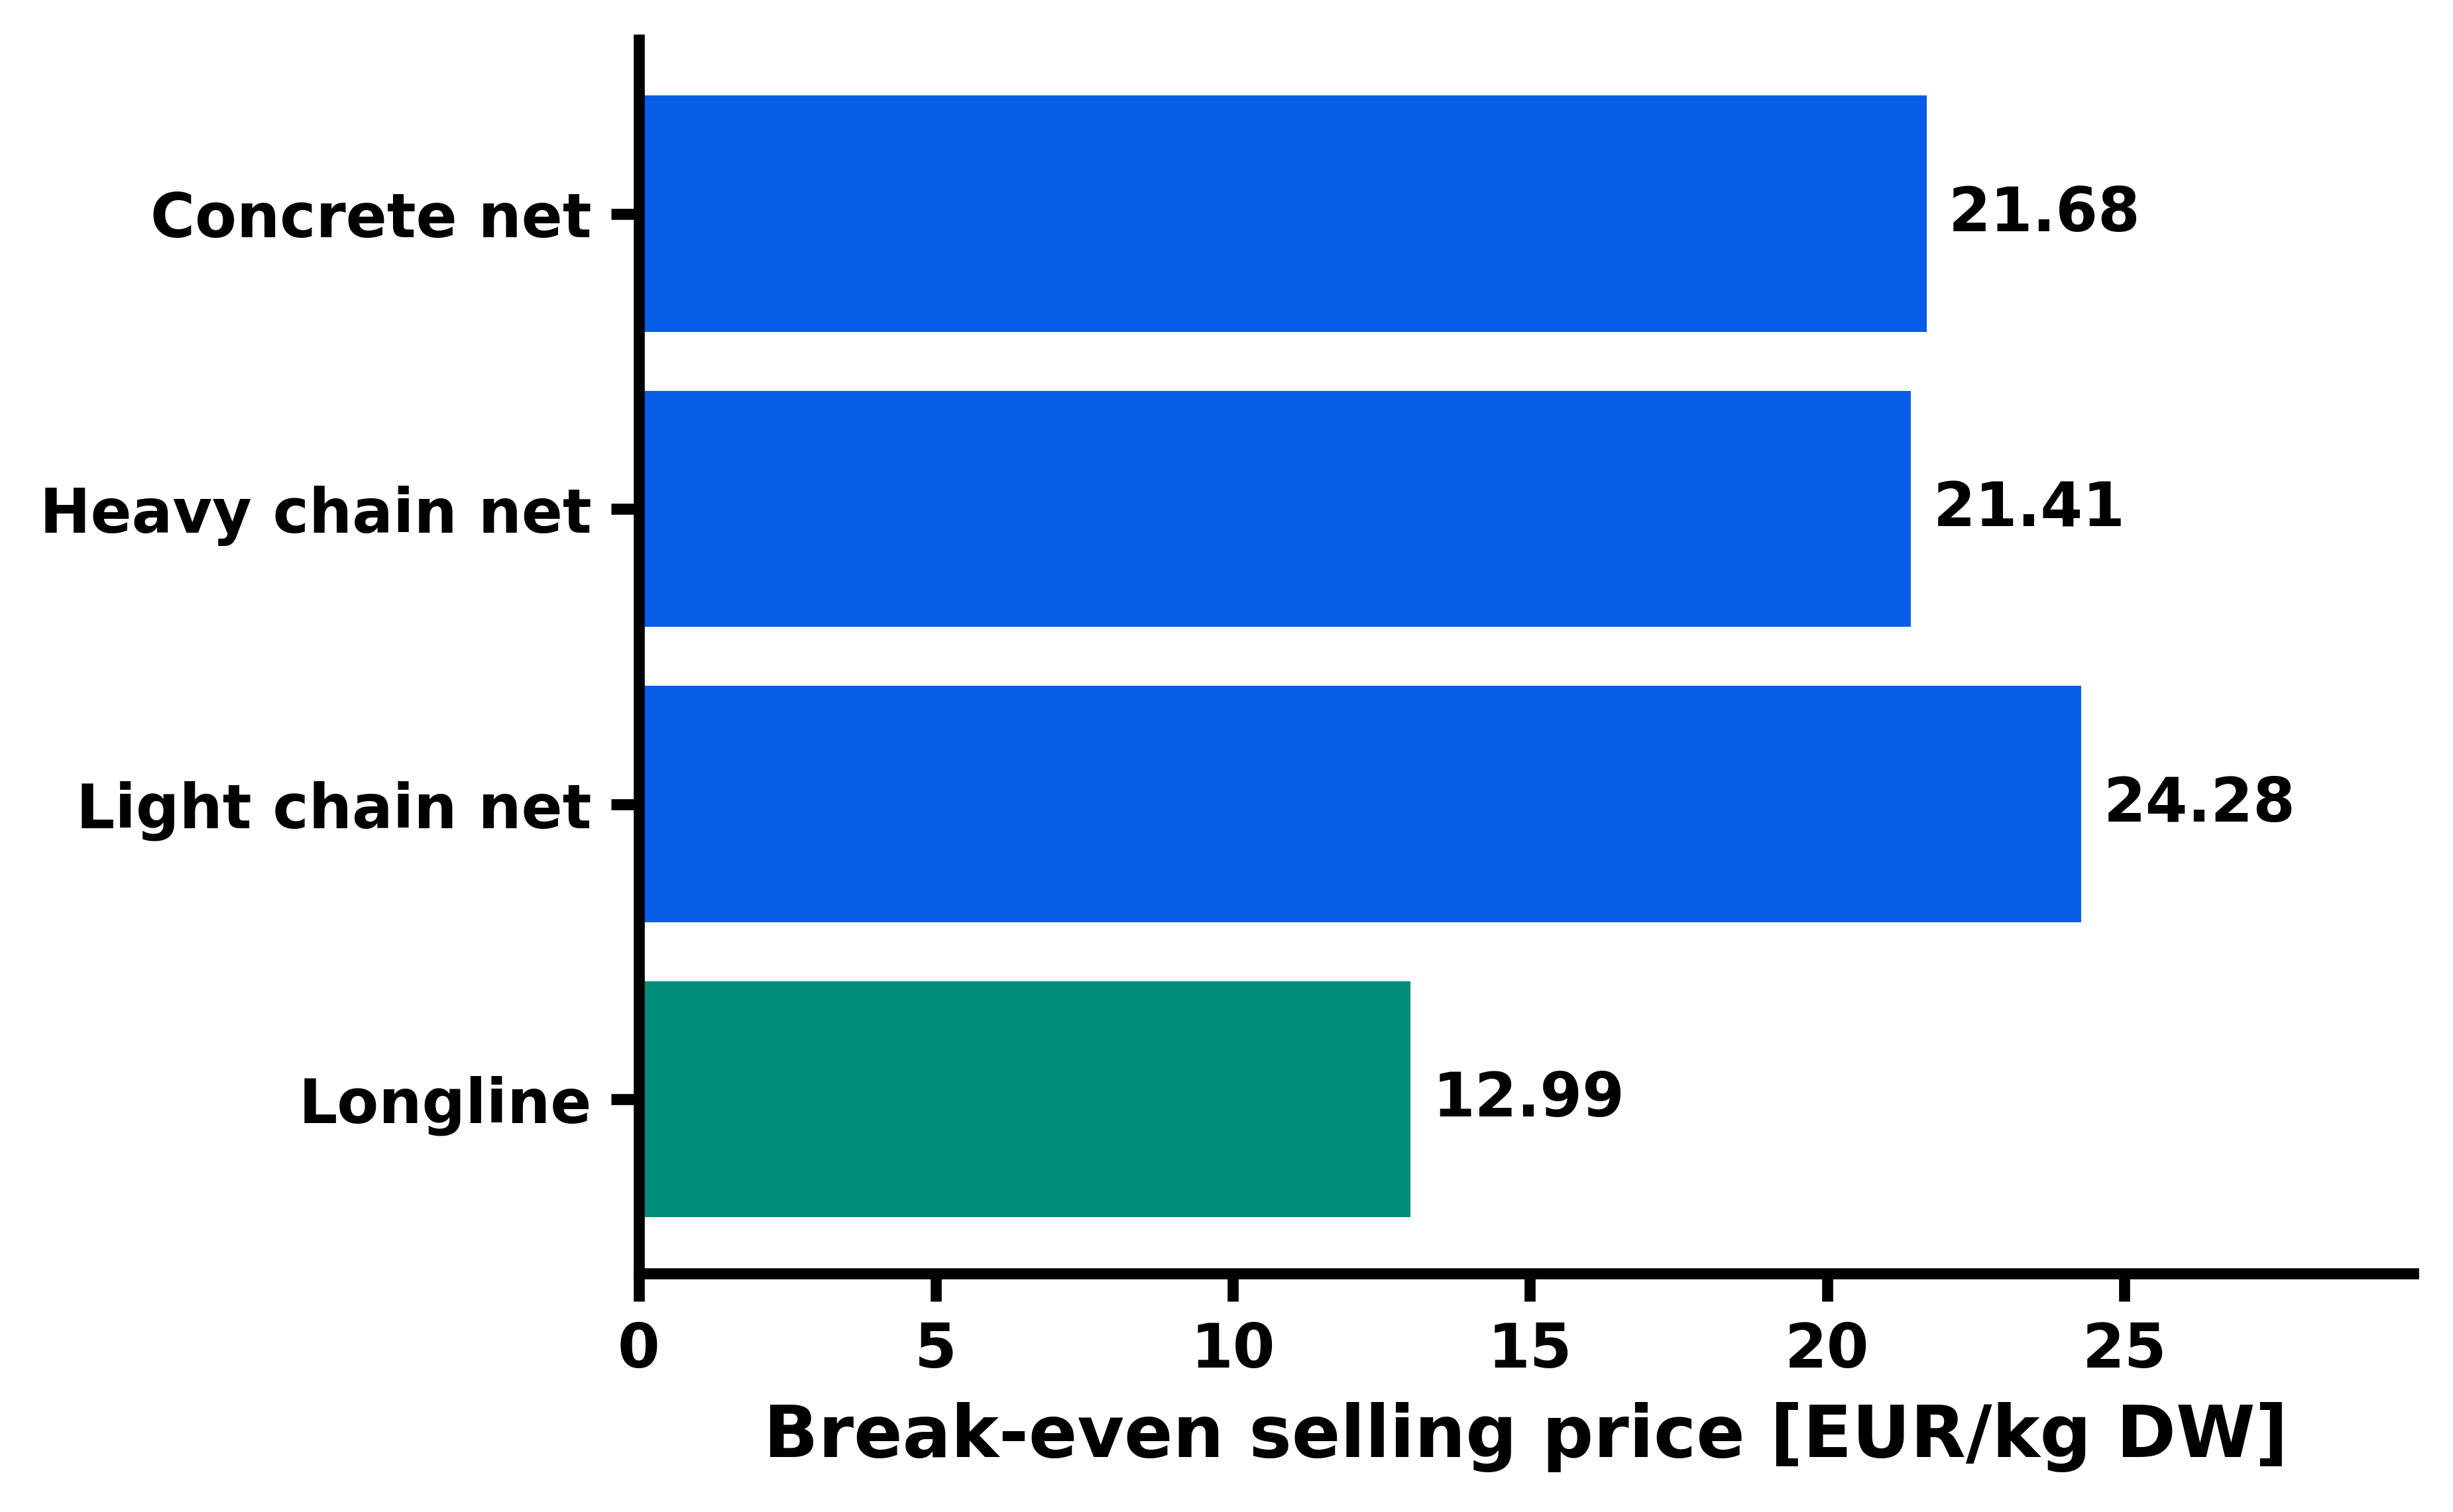

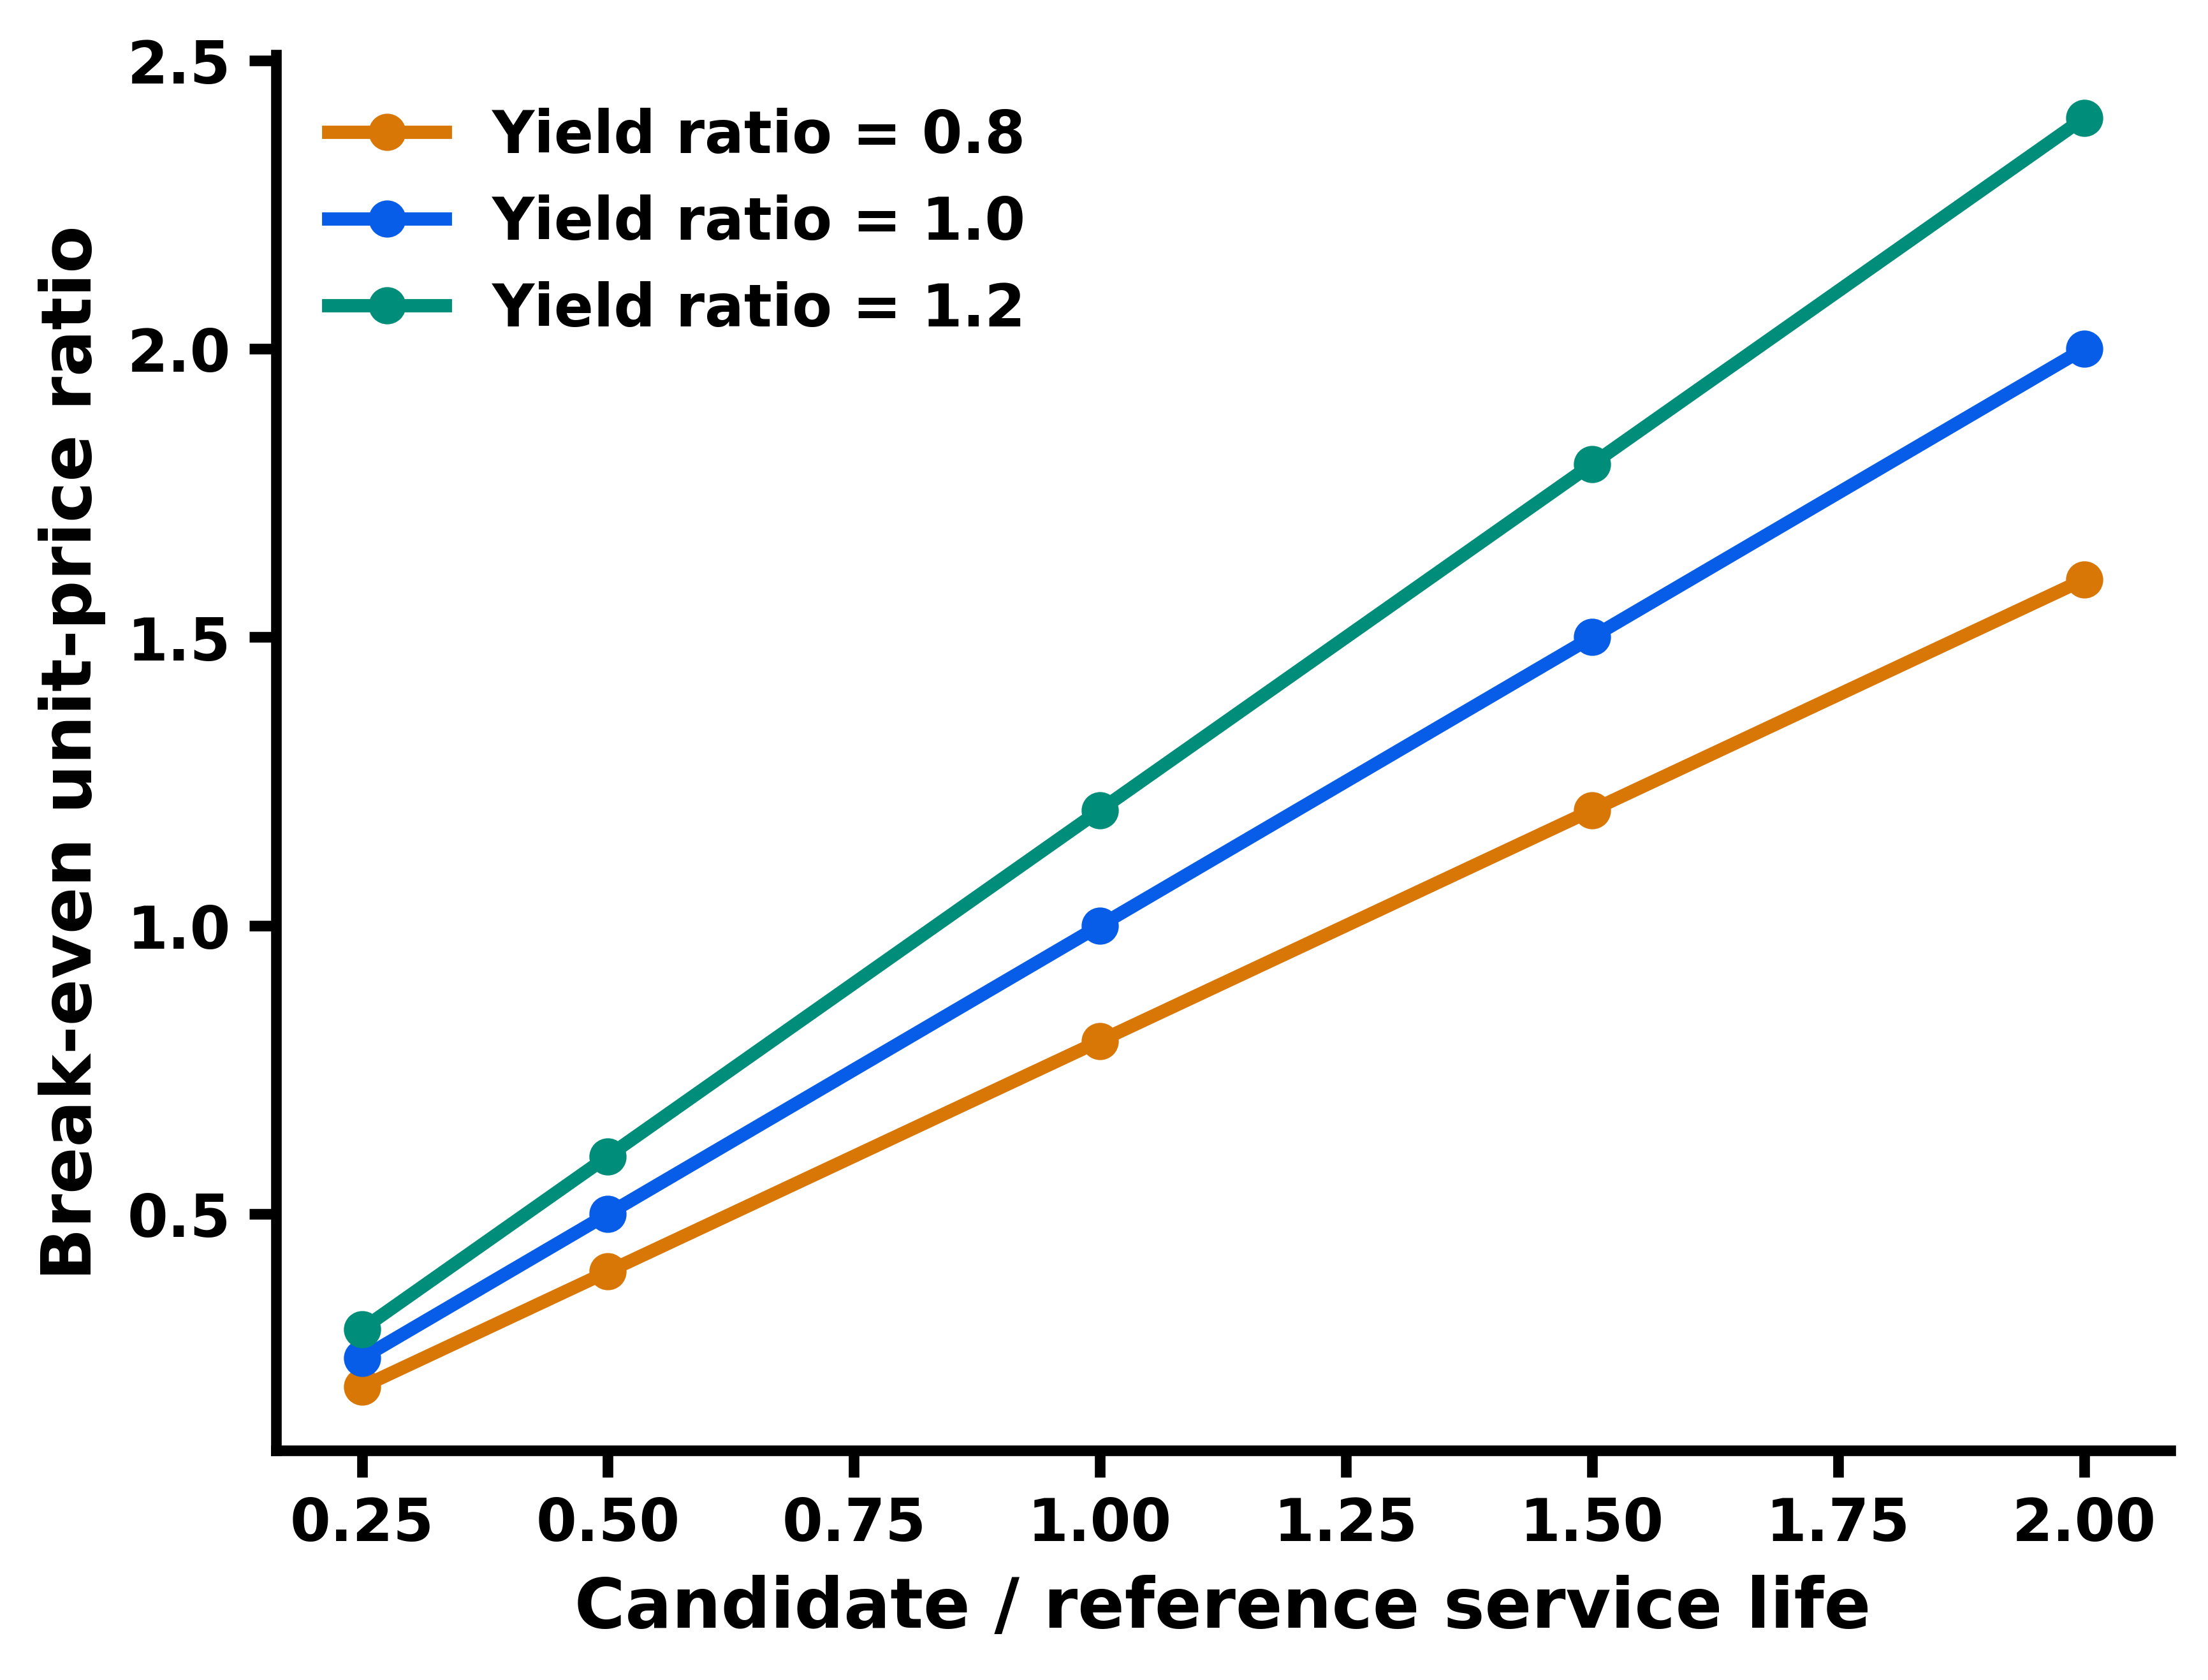

In [2]:
from IPython.display import display, Image
for name in ["gwp_comparison", "break_even_price", "replacement_break_even"]:
    display(Image(filename=str(OUT/(name+".png")), width=680))